# Tiedonkäsittely Pythonilla (4 op)
#### Tekijä: Roni Pihajoki
Lisätään tarvittavat kirjastot & datasetti käyttöön

In [919]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

%matplotlib inline

df = pd.read_csv('WorkPlaceSatisfactionSurveyData.csv', encoding='utf-8')

## Miltä datasetti näyttää, mitä se pitää sisällään & montako riviä/saraketta siinä on
Ensin on tuloste rivien & sarakkeiden määristä <br>
Sen jälkeen on tuloste taulukon kolmesta ensimmäisestä rivistä <br>
Tästä näemme sarakeotsikot & esimerkit arvoista, joita taulukko sisältää <br>
Tämän pohjalta saamme ajatuksen, mitä dataa meillä on & mitä kaikkea voimme sillä tehdä <br>


In [920]:
print("Rivien lukumäärä: ",df.shape[0])
print("Sarakkeiden lukumäärä: ",df.shape[1])
print()
print("Tietoja taulukost:")
df.info()
print()
print("Kolme ensimmäistä riviä:")
df.head(3)


Rivien lukumäärä:  82
Sarakkeiden lukumäärä:  16

Tietoja taulukost:
<class 'pandas.DataFrame'>
RangeIndex: 82 entries, 0 to 81
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   number                  82 non-null     int64  
 1   gender                  82 non-null     int64  
 2   age                     82 non-null     int64  
 3   family                  82 non-null     int64  
 4   education               81 non-null     float64
 5   years_of_service        80 non-null     float64
 6   salary                  82 non-null     int64  
 7   sat_management          82 non-null     int64  
 8   sat_colleques           81 non-null     float64
 9   sat_workingEnvironment  82 non-null     int64  
 10  sat_salary              82 non-null     int64  
 11  sat_tasks               82 non-null     int64  
 12  holidayCabin            20 non-null     float64
 13  gym                     9 non-null     

,number,gender,age,family,education,years_of_service,salary,sat_management,sat_colleques,sat_workingEnvironment,sat_salary,sat_tasks,holidayCabin,gym,muscleCare,healtcare
0,1,1,38,1,1.0,22.0,3587,3,3.0,3,3,3,NaN,NaN,NaN,NaN
1,2,1,29,2,2.0,10.0,2963,1,5.0,2,1,3,NaN,NaN,NaN,NaN
2,3,1,30,1,1.0,7.0,1989,3,4.0,1,1,3,NaN,NaN,NaN,1.0


# Projektin esittely
Minulle tuli seuraavat taustamuuttujat käsiteltäväksi:
- Education (Sarake E) = Luokkamuuttuja
- Salary (Sarake G) = Numeerinen muuttuja

Sat_sarakkeet ovat "tyytyväisyys" sarakkeita: <br>
- sat_management = Tämä kertoo kuinka tyytyväisiä johdosta ollaan
- sat_colleques = Tämä kertoo kuinka tyytyväisiä kolleegoista ollaan
- sat_workingEnvironment = Tämä kertoo kuinka tyytyväisiä työympäristöön ollaan
- sat_salary = Tämä kertoo kuinka tyytyväisiä palkkaan ollaan
- sat_tasks = Tämä kertoo kuinka tyytyväisiä työtehtäviin ollaan

Projektissa on ideana että käsitellään ensin jokainen taustamuuttuja & sat_muuttuja erikseen<br>
(esimerkiksi palkan keskiarvo, korkein palkka tai matalin palkka)<br>
Kun yksittäis analysointi on valmista, alamme tutkimaan taustamuuttujia & sat_muuttujia yhdessä<br>
(esimerkiksi miten korkeimman palkan saaja kokee tyytyväisyytensä työympäristöön)<br>
Yhteensä tehdään siis 10 yhdistelmä analysointia & 7 erillistä muuttuja kohtaista analysointia<br>

### Muuttujien arvojen selvennys
Education (Korkein suoritettu tutkinto):
- 1 = peruskoulu tutkinto
- 2 = toisen asteen tutkinto
- 3 = Kandidaatin tutkinto
- 4 = Maisterin tutkinto

Salary:
- Kuukauden palkka euroina

sat_muuttujat:
- Asteikolla 1-5
- 1 tarkoittaa erittäin tyytymätöntä
- 5 tarkoittaa erittäin tyytyväistä

## Taulukon siistiminen
Tiputetaan taulukosta meille turhat sarakkeet käyttäen .drop komentoa<br>
1. Tulostetaan tämän hetkisten sarakkeiden nimet
2. Tiputetaan sieltä 4 viimeistä saraketta, joita me emme käytä analyysissämme
3. Tulostetaan 3 ensimmäistä riviä uudestaan, josta näemme että sarakkeet on poistettu oikein

In [921]:
df.columns

Index(['number', 'gender', 'age', 'family', 'education', 'years_of_service',
       'salary', 'sat_management', 'sat_colleques', 'sat_workingEnvironment',
       'sat_salary', 'sat_tasks', 'holidayCabin', 'gym', 'muscleCare',
       'healtcare'],
      dtype='str')

In [922]:
df= df.drop(columns=['holidayCabin', 'gym', 'muscleCare', 'healtcare'])



In [923]:
df.head(1)

,number,gender,age,family,education,years_of_service,salary,sat_management,sat_colleques,sat_workingEnvironment,sat_salary,sat_tasks
0,1,1,38,1,1.0,22.0,3587,3,3.0,3,3,3


Tiputetaan myös minulle turhat sarakkeet, joita en käytä omassa analyysissani

In [924]:
df = df.drop(columns=['number', 'gender', 'age', 'family', 'years_of_service'])
df.head(1)

,education,salary,sat_management,sat_colleques,sat_workingEnvironment,sat_salary,sat_tasks
0,1.0,3587,3,3.0,3,3,3


### Vaihdetaan sarakkeiden nimet suomenkielisiksi

In [925]:
df2 = df
df2.columns = ['koulutus', 'palkka', 'sat_johto', 'sat_kolleegat','sat_tyoYmparisto','sat_palkka','sat_tyoTehtavat']
df2.head(1)

,koulutus,palkka,sat_johto,sat_kolleegat,sat_tyoYmparisto,sat_palkka,sat_tyoTehtavat
0,1.0,3587,3,3.0,3,3,3


Tarkastellaan vielä tietoja taulukosta, kuten keskiarvoja, minimeitä ja maksimeita.

#### Tarkistetaan puuttuvat arvot

In [926]:
df2.isnull().sum()

koulutus            1
palkka              0
sat_johto           0
sat_kolleegat       1
sat_tyoYmparisto    0
sat_palkka          0
sat_tyoTehtavat     0
dtype: int64

#### Taulukon uniikit arvot

In [927]:
for var in df2:
    print(var, df2[var].unique())

koulutus [ 1.  2.  3.  4. nan]
palkka [3587 2963 1989 2144 2183 1910 2066 2768 2106 2651 2846 2808 3393 2691
 5225 2729 2925 2457 4874 3510 4446 1521 2223 1949 2340 6278 1559 2027
 2300 2534 1872 2261 2417 3119 2574 1715 5069 2495 3470 1598 1638 2612]
sat_johto [3 1 2 4 5]
sat_kolleegat [ 3.  5.  4.  2. nan]
sat_tyoYmparisto [3 2 1 5 4]
sat_palkka [3 1 2 4 5]
sat_tyoTehtavat [3 2 4 1 5]


# Taustamuuttujat

### Education Luokkamuuttuja


Mikä on korkein henkilön suorittama tutkinto<br>
- Peruskoulu tutkintoja korkeimpana suorituksena on 27 henkilöllä<br>
- Toisen asteen tutkintoja korkeimpana suorituksena on 30 henkilöllä<br>
- Kanditaatti tason tutkintoja korkeimpana suorituksena on 22 henkilöllä<br>
- Maisteri tason tutkintoja koirkaimpana suorituksena on 2 henkilöllä<br>
<br>
Vaihdetaan alla olevaan taulukkoon oikeat rivi otsikot


In [928]:
dfe=pd.crosstab(df2['koulutus'], 'kpl')
dfe.index=['Peruskoulu', 'Toinen aste', 'Kanditaatti', 'Maisteri']
dfe.columns.name='Suoritetun tutkinnon taso'
dfe

Suoritetun tutkinnon taso,kpl
Peruskoulu,27
Toinen aste,30
Kanditaatti,22
Maisteri,2


Lasketaan suoritettujen tutkintojen määrä

In [929]:
edu_caunt = sum(dfe['kpl'])
edu_caunt

81

Kaavio kuvaa tutkintojen jakaumaa

Text(0.5, 0, 'kpl, N = 81')

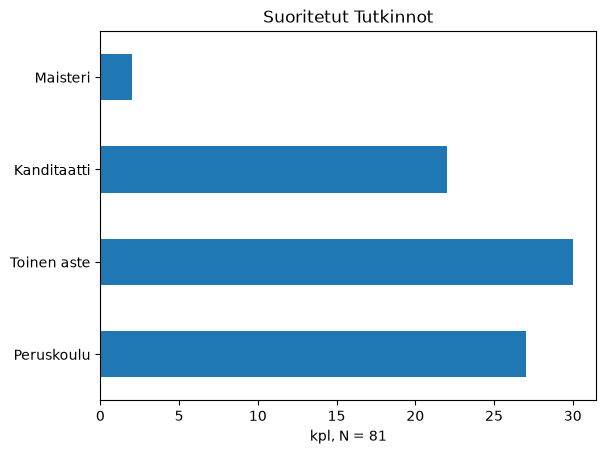

In [930]:
dfe.plot.barh(legend = False)
plt.title('Suoritetut Tutkinnot')
plt.xlabel('kpl, N = 81')

Koulutusten keskiarvo, minimi, maksimi ja poikkeama <br>
Erikseen kirjattu mediaani & varianssi, koska ne puuttuvat taulukosta

In [931]:
e_mediaani = df2['koulutus'].median()
e_varianssi = df2['koulutus'].var()

print("Koulutusten mediaani on  {:.0f}".format(e_mediaani))
print("Koulutusten varianssi on  {:.2f}".format(e_varianssi))

df2.describe()[["koulutus"] ]

Koulutusten mediaani on  2
Koulutusten varianssi on  0.71


,koulutus
count,81.000000
mean,1.987654
std,0.844006
min,1.000000
25%,1.000000
50%,2.000000
75%,3.000000
max,4.000000


Korkeamman koulutustason omaavien muut sarakkeet eli korkein suoritettu tutkinto on maisterin

In [932]:
df2.nlargest(n=2, columns = 'koulutus')

,koulutus,palkka,sat_johto,sat_kolleegat,sat_tyoYmparisto,sat_palkka,sat_tyoTehtavat
16,4.0,5225,5,5.0,5,4,5
66,4.0,5069,3,4.0,3,2,2


Matalamman koulutustason omaavien muut sarakkeet eli korkein suoritettu tutkinto on peruskoulu

In [933]:
df2.nsmallest(n=27, columns = 'koulutus')

,koulutus,palkka,sat_johto,sat_kolleegat,sat_tyoYmparisto,sat_palkka,sat_tyoTehtavat
0,1.0,3587,3,3.0,3,3,3
2,1.0,1989,3,4.0,1,1,3
3,1.0,2144,3,3.0,3,3,3
7,1.0,2066,3,5.0,3,1,3
8,1.0,2768,2,4.0,4,2,4
9,1.0,2106,3,2.0,1,1,1
10,1.0,2651,3,5.0,3,1,3
22,1.0,3510,4,4.0,4,4,4
27,1.0,2223,3,4.0,3,2,4
31,1.0,2925,4,4.0,4,3,4


Boxplot<br>
Tästä voimme nähdä miten 4.0 eli maisterin tutkinto on "poikkeama"<br>
81 tutkinnosta vain 2 on maistereita<br>

Text(0.5, 0, 'Korkein suoritettu tutkinto, n=81')

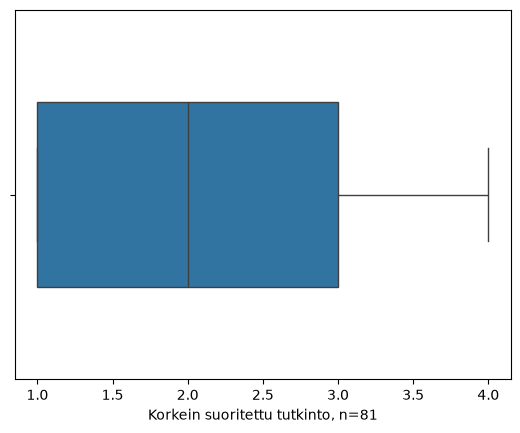

In [934]:
bp1 = sns.boxplot(x = df2['koulutus'],width=.5)

bp1.set_xlabel('Korkein suoritettu tutkinto, n=' + str(df2['koulutus'].count()))

Katsotaan vielä jakaumaa prosenttien kannalta

In [935]:
dfePros = pd.crosstab(df2['koulutus'], 'kpl')
dfePros['%'] = dfePros['kpl'] / dfePros['kpl'].sum() * 100
dfePros.index=['Peruskoulu', 'Toinen aste', 'Kanditaatti', 'Maisteri']
dfePros.columns.name='Suoritetun tutkinnon taso'
dfePros

Suoritetun tutkinnon taso,kpl,%
Peruskoulu,27,33.333333
Toinen aste,30,37.037037
Kanditaatti,22,27.160494
Maisteri,2,2.469136


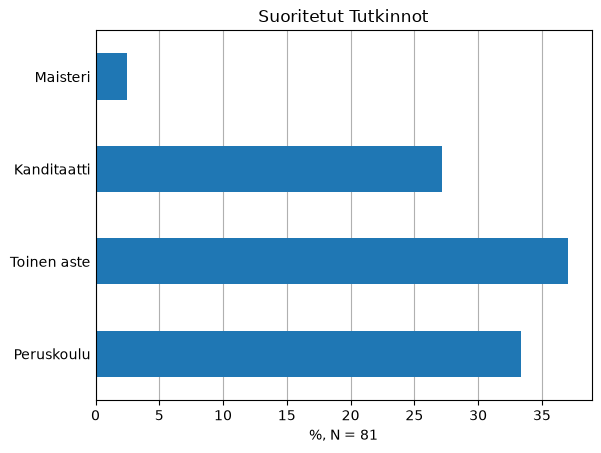

In [936]:
dfePros['%'].plot.barh(zorder = 2)
plt.title('Suoritetut Tutkinnot')
plt.xlabel('%, N = ' + str(dfePros['kpl'].sum()))
plt.grid(axis = 'x')
plt.tick_params(axis = 'y', length = 0)


### Salary numeerinen muttuja

Palkkojen keskiarvo, minimi, maksimi ja poikkeama <br>
Erikseen kirjattu mediaani, koska se puuttui taulukosta

In [937]:
dfp = df2
s_mediaani = dfp['palkka'].median()
print("Palkan mediaani on  {:.0f}".format(s_mediaani))
dfp.describe()[["palkka"]]

Palkan mediaani on  2320


,palkka
count,82.000000
mean,2563.878049
std,849.350302
min,1521.000000
25%,2027.000000
50%,2320.000000
75%,2808.000000
max,6278.000000


Luodaan numeeriselle muuttujalle "palkka" luokitelluksimuuttujaksi "palkkataso"

In [938]:
bins = [1000, 2000, 3000, 4000, 5000, 6000, 7000]
dfp['palkkataso'] = pd.cut(dfp['palkka'], bins = bins)
dfp

,koulutus,palkka,sat_johto,sat_kolleegat,sat_tyoYmparisto,sat_palkka,sat_tyoTehtavat,palkkataso
0,1.0,3587,3,3.0,3,3,3,"(3000, 4000]"
1,2.0,2963,1,5.0,2,1,3,"(2000, 3000]"
2,1.0,1989,3,4.0,1,1,3,"(1000, 2000]"
3,1.0,2144,3,3.0,3,3,3,"(2000, 3000]"
4,2.0,2183,2,3.0,2,1,2,"(2000, 3000]"
...,...,...,...,...,...,...,...,...
77,3.0,1598,4,4.0,4,3,4,"(1000, 2000]"
78,1.0,1638,1,3.0,2,1,2,"(1000, 2000]"
79,2.0,2612,3,4.0,3,3,3,"(2000, 3000]"
80,2.0,2808,3,4.0,3,3,3,"(2000, 3000]"


Tarkistetaan palkkatasojen prosentti osuudet

In [939]:
dfpPros = pd.crosstab(dfp['palkkataso'], 'kpl')
dfpPros.columns.name = ' '
n = dfpPros['kpl'].sum()
dfpPros['%'] = dfpPros / n * 100
dfpPros

,kpl,%
palkkataso,,
"(1000, 2000]",19,23.170732
"(2000, 3000]",50,60.975610
"(3000, 4000]",8,9.756098
"(4000, 5000]",2,2.439024
"(5000, 6000]",2,2.439024
"(6000, 7000]",1,1.219512


Vaihdetaan data tyyppi String muotoon, jotta saamme laskettua "yhteensä" rivin

In [940]:
type(dfpPros.index.values[0])

pandas.Interval

In [941]:
dfpPros.index = dfpPros.index.astype(str)
dfpPros.loc['Yhteensä'] = dfpPros.sum()
dfpPros

,kpl,%
palkkataso,,
"(1000, 2000]",19.0,23.170732
"(2000, 3000]",50.0,60.975610
"(3000, 4000]",8.0,9.756098
"(4000, 5000]",2.0,2.439024
"(5000, 6000]",2.0,2.439024
"(6000, 7000]",1.0,1.219512
Yhteensä,82.0,100.000000


In [942]:
type(dfpPros.index.values[0])

str

#### Boxplot

Text(0.5, 0, 'Palkka, n=82')

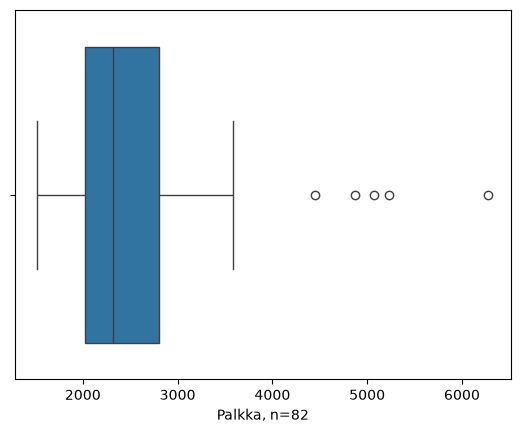

In [943]:
bp2 = sns.boxplot(x = dfp['palkka'])

bp2.set_xlabel('Palkka, n=' + str(dfp['palkka'].count()))

Kaaviot

Text(0, 0.5, 'kappale määrä, n=82')

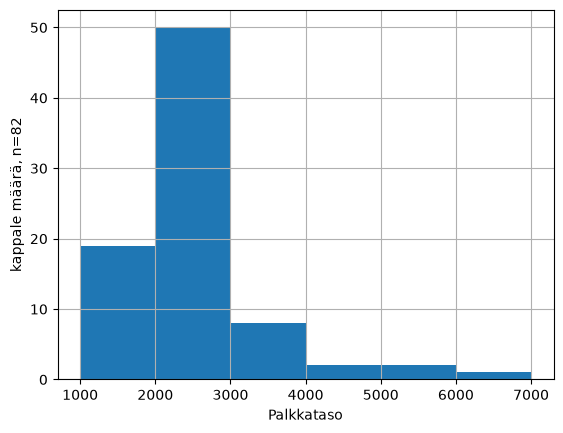

In [944]:
dfp['palkka'].hist(bins = bins)
plt.xlabel('Palkkataso')
plt.ylabel('kappale määrä, n=' + str(n))

Text(0, 0.5, '%, n =82')

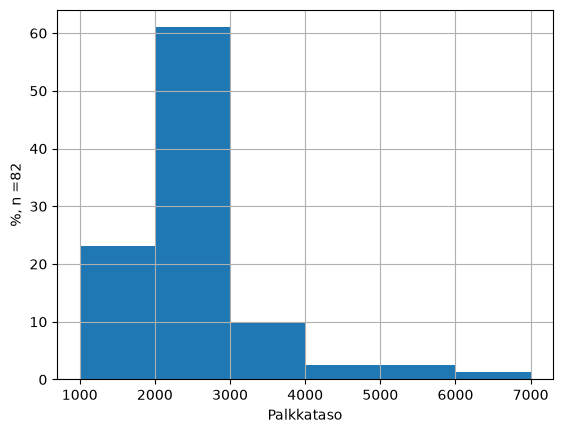

In [945]:
dfp['palkka'].hist(bins = bins, weights = np.ones(n) / n * 100)

plt.xlabel('Palkkataso')
plt.ylabel('%, n =' + str(n))

Tarkastellaan tarkemmin suurinta palkkaluokan jakaumaa 2000-3000

In [946]:
binsT = [2000, 2250, 2500, 2750, 3000]
dfp['palkkatasoJakauma'] = pd.cut(dfp['palkka'], bins = binsT)
dfpJakauma = pd.crosstab(dfp['palkkatasoJakauma'], 'kpl')
dfpJakauma.columns.name = ' '
n = dfpJakauma['kpl'].sum()
dfpJakauma['%'] = dfpJakauma / n * 100
dfpJakauma

,kpl,%
palkkatasoJakauma,,
"(2000, 2250]",19,38.0
"(2250, 2500]",9,18.0
"(2500, 2750]",11,22.0
"(2750, 3000]",11,22.0


Text(0, 0.5, 'Kpl, n=50')

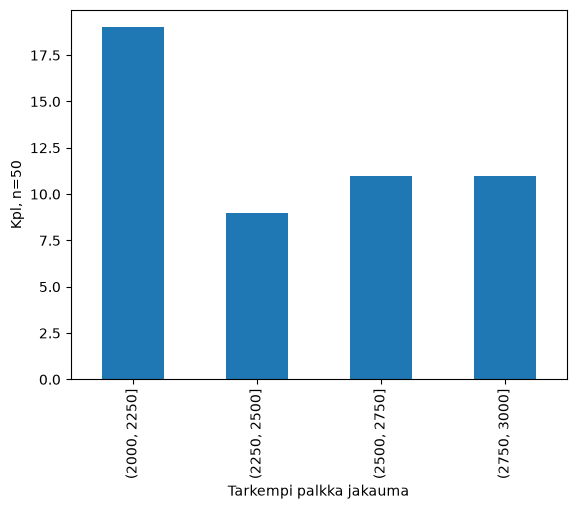

In [947]:
palkkaJakaumat = pd.cut(dfp['palkka'], bins = binsT, right = True)
palkkaJakaumat.value_counts(sort = False).plot( kind = 'bar')

plt.xlabel('Tarkempi palkka jakauma')
plt.ylabel('Kpl, n=' + str(n))

# Sat_Muuttujat

### sat_management eli sat_johto

In [948]:
dfsj = df

In [949]:
sj = pd.crosstab(df['sat_johto'], 'kpl')
sj.columns.name=''
sj

,kpl
sat_johto,
1,7
2,16
3,30
4,23
5,6


Text(0.5, 0, 'Net house income, n=82')

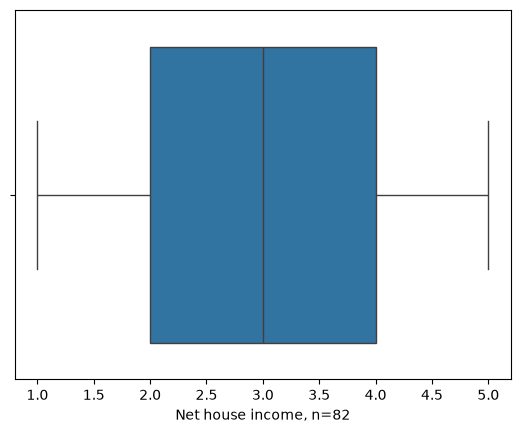

In [950]:
bp3 = sns.boxplot(x = dfsj['sat_johto'])

bp3.set_xlabel('Net house income, n=' + str(dfsj['sat_johto'].count()))

### sat_colleques eli sat_kolleegat

In [951]:
dfsk = df

In [952]:
sk = pd.crosstab(dfsk['sat_kolleegat'], 'kpl')
sk.columns.name=''
sk

,kpl
sat_kolleegat,
2.0,3
3.0,16
4.0,35
5.0,27


Text(0.5, 0, 'Net house income, n=81')

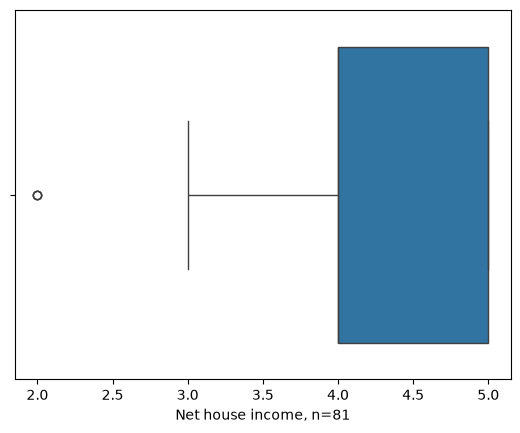

In [953]:
bp4 = sns.boxplot(x = dfsk['sat_kolleegat'])

bp4.set_xlabel('Net house income, n=' + str(dfsk['sat_kolleegat'].count()))

### sat_workingEnvironment eli sat_tyoYmparisto

In [954]:
dfstY = df

In [955]:
stY = pd.crosstab(dfstY['sat_tyoYmparisto'], 'kpl')
stY.columns.name=''
stY

,kpl
sat_tyoYmparisto,
1,9
2,9
3,30
4,23
5,11


Text(0.5, 0, 'Net house income, n=82')

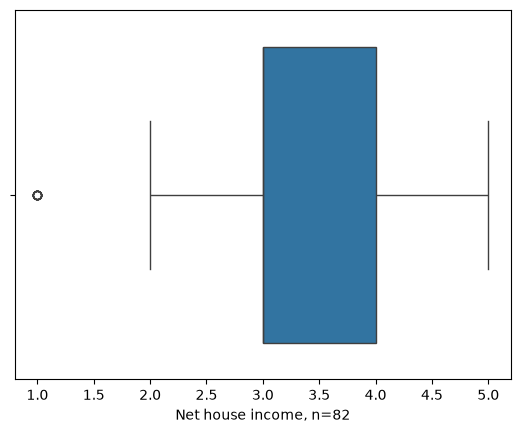

In [956]:
bp5 = sns.boxplot(x = dfstY['sat_tyoYmparisto'])

bp5.set_xlabel('Net house income, n=' + str(dfstY['sat_tyoYmparisto'].count()))

### sat_salary eli sat_palkka

In [957]:
dfsp = df

In [958]:
sp = pd.crosstab(dfsp['sat_palkka'], 'kpl')
sp.columns.name=''
sp

,kpl
sat_palkka,
1,33
2,19
3,19
4,10
5,1


Kappas, vain yksi henkilö on erittäin tyytyväinen palkkaansa<br>
Tulostetaampa tämä rivi niin nähdään millainen kaveri on kyseessä<br>

In [959]:
dfsp.nlargest(n = 1, columns = 'sat_palkka')

,koulutus,palkka,sat_johto,sat_kolleegat,sat_tyoYmparisto,sat_palkka,sat_tyoTehtavat,palkkataso,palkkatasoJakauma
36,2.0,2729,5,5.0,5,5,5,"(2000, 3000]","(2500, 2750]"


Tämä taitaa olla legendaarinen "kaikki on tosi hyvin, kysely pois alta niin voin jatkaa töitä" tyypin kaveri

Text(0.5, 0, 'Net house income, n=82')

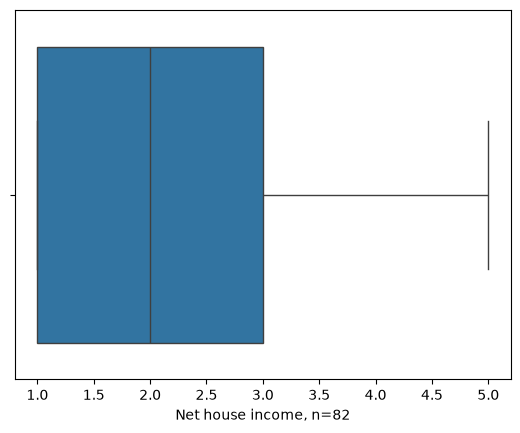

In [960]:
bp6 = sns.boxplot(x = dfsp['sat_palkka'])

bp6.set_xlabel('Net house income, n=' + str(dfsp['sat_palkka'].count()))

### sat_tasks eli sat_tyoTehtavat


In [961]:
dfstT = df

In [962]:
stT = pd.crosstab(dfstT['sat_tyoTehtavat'], 'kpl')
stT.columns.name=''
stT

,kpl
sat_tyoTehtavat,
1,5
2,15
3,29
4,25
5,8


In [963]:
dfstT.nsmallest(n = 5, columns = 'sat_tyoTehtavat')

,koulutus,palkka,sat_johto,sat_kolleegat,sat_tyoYmparisto,sat_palkka,sat_tyoTehtavat,palkkataso,palkkatasoJakauma
9,1.0,2106,3,2.0,1,1,1,"(2000, 3000]","(2000.0, 2250.0]"
17,3.0,2729,4,3.0,4,2,1,"(2000, 3000]","(2500.0, 2750.0]"
52,1.0,1989,1,2.0,2,1,1,"(1000, 2000]",NaN
74,1.0,1949,1,5.0,1,1,1,"(1000, 2000]",NaN
75,2.0,1598,1,5.0,1,1,1,"(1000, 2000]",NaN


Text(0.5, 0, 'Net house income, n=82')

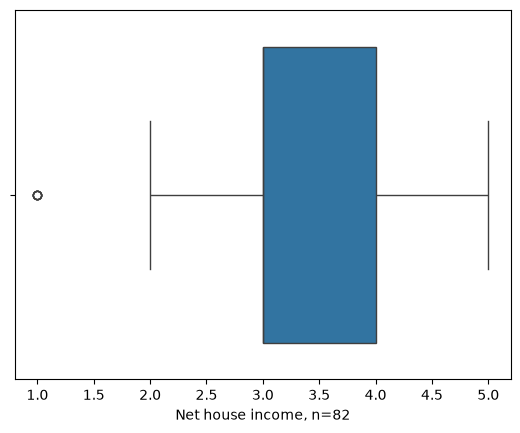

In [964]:
bp7 = sns.boxplot(x = dfstT['sat_tyoTehtavat'])

bp7.set_xlabel('Net house income, n=' + str(dfstT['sat_tyoTehtavat'].count()))

# Taustamuuttujien & Sat_muuttujien ristiin vertailu

In [965]:
df = df.drop(columns=['palkkatasoJakauma'])
df.head(1)

,koulutus,palkka,sat_johto,sat_kolleegat,sat_tyoYmparisto,sat_palkka,sat_tyoTehtavat,palkkataso
0,1.0,3587,3,3.0,3,3,3,"(3000, 4000]"


### Koulutus & sat_johto

In [971]:
dfksj = df
dfksj = pd.crosstab(dfksj['sat_johto'], dfksj['koulutus'], normalize = 'columns') * 100
dfksj.columns = ['Peruskoulu', 'Toinen aste', 'Kanditaatti', 'Maisteri']
dfksj.columns.name=''
dfksj


,Peruskoulu,Toinen aste,Kanditaatti,Maisteri
sat_johto,,,,
1,18.518519,6.666667,0.000000,0.0
2,11.111111,26.666667,22.727273,0.0
3,37.037037,36.666667,36.363636,50.0
4,22.222222,26.666667,36.363636,0.0
5,11.111111,3.333333,4.545455,50.0


### Koulutus & sat_kolleegat

### Koulutus & sat_tyoYmparisto

### Koulutus & sat_palkka

### Koulutus & sat_tyoTehtavat

### palkkataso & sat_johto

### palkkataso & sat_kolleegat

### palkkataso & sat_tyoYmparisto

### palkkataso & sat_palkka

### palkkataso & sat_tyoTehtavat